# 4. Running the model: SDDP with good-deal bounds

This notebook ties everything together. All parameters are set in the first code cell; the data-derived ones are read
from `data/processed/` if notebooks 1–3 have been run, otherwise literature values are used.

**What is computed.** A producer schedules two reservoirs over $T$ weeks under uncertain prices and inflows and can sell
forward contracts. We train three policies with SDDP:

* **risk neutral**: next week's value is weighted by the physical probabilities $\delta$;
* **good-deal** at one or more Sharpe bounds $h$: next week's value is weighted by the worst-case measure $q^*$ that
  (i) stays within a $\chi^2$-distance $h^2/52$ of $\delta$ and (ii) prices every live forward correctly (martingale
  constraints). $q^*$ is the solution of a small convex QCQP at every node of the backward pass (Gurobi, `gdsddp/gooddeal.py`).

The good-deal policy value is a **lower bound on the value of the plant** that no investor with access to the forwards
would consider a "too good deal"; the gap to the risk-neutral value is the price of the risk the forwards cannot hedge,
mainly inflow. Because the martingale constraints pin the price directions, the distortion lands on inflow: the
good-deal policy keeps more water in store (insurance against dry weeks).

As committed, the parameter cell holds the settings of a 102-week, 200-state run (hours and about 50 GB); `T = 52`, `K = 50`, `N_LATTICE_PATHS = 5000`, `N_SIM_PATHS = 300` give a laptop run of about half an hour.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gdsddp import plots
from gdsddp.data import RAW, SAMPLE, PROCESSED, save_json, load_json
plots.style()
PROCESSED.mkdir(parents=True, exist_ok=True)
from gdsddp.models import PriceModel, InflowModel, simulate_paths
from gdsddp.lattice import build_lattice, Lattice
from gdsddp.contracts import Contract, ContractSystem
from gdsddp.hydro import Reservoir, Cascade, Economics
from gdsddp.sddp import SDDPConfig, train
from gdsddp.simulate import simulate, revenue_summary

## Parameters

In [2]:
RUN_NAME = "full_8c"              # results go to results/<RUN_NAME>/
T = 102                        # weeks in the planning horizon (the thesis uses 104)
START_WEEK = 1                # calendar week of stage 0
K = 200                        # lattice states per week
N_LATTICE_PATHS = 30000        # simulated paths the lattice is built from
H_VALUES = [0.75, 1.0]         # annual Sharpe bounds of the good-deal policies (0 = risk neutral, run always)
SDDP_ITERATIONS = 50          # maximum SDDP iterations per policy
SDDP_TOL = 1e-4               # stop when the bound moves less than this (relative) ...
SDDP_WINDOW = 10              # ... over this many iterations
N_SIM_PATHS = 500             # simulated paths per policy
SEED = 42
CHI0 = 0.0                    # short-term price deviation at stage 0: 0 = start at the long-term level xi0 (+ season)
OUT = ROOT / "results" / RUN_NAME; OUT.mkdir(parents=True, exist_ok=True)   # figures and arrays are written here

# --- price model: PCA parameters from notebook 3, season and level from notebook 1 (literature values otherwise)
price_params = load_json(PROCESSED / "price_params.json") if (PROCESSED / "price_params.json").exists() else \
    {"phi_chi": 0.977, "sigma_chi": 2.292, "sigma_xi": 0.554}                       # Kleiven et al. (2023)
season = load_json(PROCESSED / "price_season.json") if (PROCESSED / "price_season.json").exists() else \
    {"season_amplitude": 4.421, "season_phase": 2.792, "xi0": 30.0}                 # thesis table 3
price = PriceModel(phi_chi=price_params["phi_chi"], sigma_chi=price_params["sigma_chi"], sigma_xi=price_params["sigma_xi"],
                   season_amplitude=season["season_amplitude"], season_phase=season["season_phase"], xi0=season["xi0"],
                   chi0=CHI0)

# --- inflow model from notebook 2 (fitted on the sample if the processed file is missing)
if (PROCESSED / "inflow_params.json").exists():
    inflow = InflowModel.from_json(PROCESSED / "inflow_params.json")
else:
    from gdsddp.data import load_station_flows
    inflow = InflowModel.fit(load_station_flows(SAMPLE / "inflow_daily.csv"))
coupling = load_json(PROCESSED / "price_inflow_coupling.json")["rho_price_inflow"] if (PROCESSED / "price_inflow_coupling.json").exists() else -0.3

# --- the plant (thesis table 2) and the economics (thesis section 5.1)
cascade = Cascade(upper=Reservoir("Namsvatn", s_max=458, s_init=261.5, x_max=74.4, energy_factor=221.5),
                  lower=Reservoir("Tunnsjø", s_max=440, s_init=296.5, x_max=70.2, energy_factor=575.7))
econ = Economics(rf_annual=0.03, tau_C=0.22, tau_R=0.45)

# --- forward contracts: delivery weeks are stage numbers 1..T. A contract is "live" (and imposes a martingale
# constraint on q*) from week 0 until its delivery ends. This set (the thesis' 8-contract case) keeps at least one
# contract live in every week of the two years, so the price is hedgeable over the whole horizon and the good-deal
# budget falls on inflow throughout. With fewer contracts (e.g. only Q2 and H2) the second year is unhedged and the
# worst-case measure tilts the price there as well.
contracts = [Contract("Feb", 5, 8), Contract("Mar", 9, 13), Contract("Apr", 14, 17), Contract("Q2", 14, 26),
             Contract("Q3", 27, 39), Contract("Q4", 40, 52), Contract("Q1y2", 53, 65), Contract("Y2", 53, 102)]

print(price); print(f"inflow model fitted on {inflow.n_years} years; price–inflow innovation correlation {coupling:+.2f}")
print(f"weekly discount factor beta = {econ.beta:.5f}, tax on revenue tau = {econ.tau:.2f}")

PriceModel(phi_chi=0.973977255159174, sigma_chi=2.6249844634912267, sigma_xi=0.5070211986768235, season_amplitude=3.996188379223248, season_phase=50.7928101651273, xi0=36.174546710050365, chi0=0.0)
inflow model fitted on 35 years; price–inflow innovation correlation -0.22
weekly discount factor beta = 0.99956, tax on revenue tau = 0.67


## Step 1 – simulate and quantise: the Markov lattice

The continuous models are simulated jointly (the inflow innovations are correlated with the price innovation at
`coupling`), and for every week ONE K-means over the four coordinates $(\chi, \xi + s, I_U, I_L)$ places $K$ states where
the paths are. Transition probabilities between the states of consecutive weeks are the empirical frequencies. The fan
plot shows the price centroids of all states; the scatter shows one week's clustering in the price–inflow plane.

lattice: 102 weeks x 200 states; 8.9% of the (standardised) variance is left within clusters
mean price over the horizon 36.1 EUR/MWh; mean successors per state 26.0


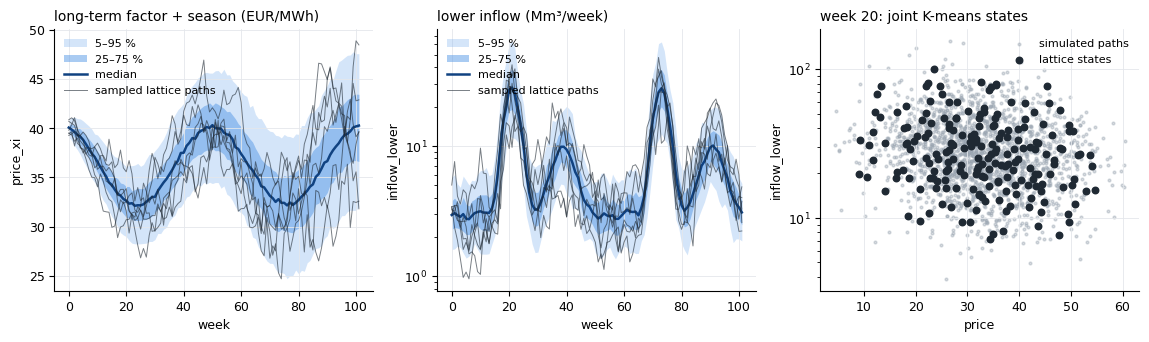

In [3]:
paths = simulate_paths(price, inflow, N_LATTICE_PATHS, T, seed=SEED, rho_price_inflow=coupling, start_week=START_WEEK)
lattice = build_lattice(paths, K, seed=SEED)
P = lattice.price_matrix()
print(f"lattice: {lattice.T} weeks x {lattice.K} states; {lattice.meta['within_variance_share']:.1%} of the (standardised) variance is left within clusters")
print(f"mean price over the horizon {P.mean():.1f} EUR/MWh; mean successors per state {np.mean([len(lattice.successors(t, m)[0]) for t in range(T - 1) for m in range(K)]):.1f}")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
plots.lattice_fan(lattice, "price_xi", "long-term factor + season (EUR/MWh)", ax=axes[0])
plots.lattice_fan(lattice, "inflow_lower", "lower inflow (Mm³/week)", ax=axes[1]); axes[1].set_yscale("log")
plots.lattice_scatter(paths, lattice, 20, "price", "inflow_lower", ax=axes[2]); axes[2].set_yscale("log")
fig.savefig(OUT / "fig_lattice.png", dpi=130, bbox_inches="tight")

## Step 2 – forward contracts on the lattice

Each contract's fair value $F_j(t, m)$ is the expected average spot price over its delivery, computed backward over the
lattice; a sold contract is struck at the week-0 fair price. The martingale check must be ~0: under the physical
probabilities the fair forward has no drift, which is the property the good-deal step preserves under $q^*$.

In [4]:
cs = ContractSystem(contracts, lattice)
print("strikes (EUR/MWh):", {k: round(v, 2) for k, v in cs.strikes.items()})
print(f"largest |E_delta[dF]| over all nodes: {cs.check_martingale():.1e}")

strikes (EUR/MWh): {'Feb': 38.53, 'Mar': 36.55, 'Apr': 34.47, 'Q2': 33.19, 'Q3': 34.19, 'Q4': 39.18, 'Q1y2': 38.18, 'Y2': 36.1}
largest |E_delta[dF]| over all nodes: 1.8e-14


## Step 3 – train the policies with SDDP

The log prints the first-stage **bound** (the policy value under the model's own measure: an upper bound that decreases
as cuts accumulate) and the revenue of the sampled forward path. The good-deal runs also report how often the QCQP had
to fall back to $\delta$ (should be 0).

[RN] seeded cuts at ['10%', '50%', '90%'] of capacity (79 s)
[RN] it   1  bound    36.840 M  forward   29.604 M  27.8 s/it
[RN] it   5  bound    35.026 M  forward   38.145 M  32.0 s/it
[RN] it  10  bound    34.327 M  forward   31.928 M  35.2 s/it
[RN] it  15  bound    34.205 M  forward   39.665 M  35.7 s/it
[RN] it  20  bound    34.101 M  forward   30.181 M  35.9 s/it
[RN] it  25  bound    34.028 M  forward   35.024 M  44.8 s/it
[RN] it  30  bound    33.945 M  forward   30.922 M  52.2 s/it
[RN] it  35  bound    33.890 M  forward   38.440 M  54.3 s/it
[RN] it  40  bound    33.854 M  forward   30.024 M  44.0 s/it
[RN] it  45  bound    33.816 M  forward   31.313 M  47.4 s/it
[RN] it  50  bound    33.797 M  forward   30.454 M  46.4 s/it
[GD h=0.75] seeded cuts at ['10%', '50%', '90%'] of capacity (231 s)
[GD h=0.75] it   1  bound    34.886 M  forward   29.452 M  76.5 s/it  q fallbacks 0
[GD h=0.75] it   5  bound    33.322 M  forward   37.743 M  78.4 s/it  q fallbacks 0
[GD h=0.75] it  10  

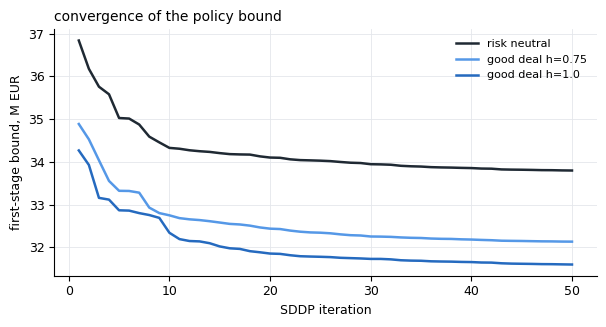

In [5]:
policies = {}
policies["risk neutral"] = train(lattice, cascade, econ, cs, SDDPConfig(iterations=SDDP_ITERATIONS, tol=SDDP_TOL, window=SDDP_WINDOW, seed=SEED, h=0.0), name="RN")
for h in H_VALUES:
    policies[f"good deal h={h}"] = train(lattice, cascade, econ, cs, SDDPConfig(iterations=SDDP_ITERATIONS, tol=SDDP_TOL, window=SDDP_WINDOW, seed=SEED, h=h), name=f"GD h={h}")
plots.convergence(policies)
plt.gcf().savefig(OUT / "fig_convergence.png", dpi=130, bbox_inches="tight")

## Step 4 – simulate the trained policies

All policies are simulated on the same physical paths (same seed), so differences in the storage trajectories and in
the revenue distribution are due to the policy, not to the draws.

In [6]:
sims = {name: simulate(pol, lattice, cascade, econ, n_paths=N_SIM_PATHS, seed=SEED + 1, log=lambda *a: None) for name, pol in policies.items()}
rows = []
for name, pol in policies.items():
    s = revenue_summary(sims[name]["total"])
    rows.append({"policy": name, "h": pol.config.h, "bound (M EUR)": pol.bound / 1e6, "mean (M EUR)": s["mean"] / 1e6, "std": s["std"] / 1e6,
                 "CVaR 5%": s["cvar5"] / 1e6, "end storage lower (Mm³)": sims[name]["storage"][:, -1, 1].mean(),
                 "end storage upper (Mm³)": sims[name]["storage"][:, -1, 0].mean(), "iterations": len(pol.history)})
table = pd.DataFrame(rows).set_index("policy")
rn = table.loc["risk neutral", "bound (M EUR)"]
table["premium vs RN (M EUR)"] = rn - table["bound (M EUR)"]
table.round(3)

,h,bound (M EUR),mean (M EUR),std,CVaR 5%,end storage lower (Mm³),end storage upper (Mm³),iterations,premium vs RN (M EUR)
policy,,,,,,,,,
risk neutral,0.00,33.797,33.096,3.878,25.754,254.951,218.161,50,0.000
good deal h=0.75,0.75,32.133,33.095,3.896,25.694,261.306,219.212,50,1.665
good deal h=1.0,1.00,31.597,33.084,3.906,25.660,261.541,220.847,50,2.200


**Reading the table.** The bound falls with $h$: the good-deal valuation discounts the unhedgeable risk, and the
difference to the risk-neutral bound is the *risk premium* the producer attaches to it. The simulated means (under the
physical measure) move much less than the bounds: the policies differ mainly in *how* they operate, and the end-of-horizon
storage shows it: the good-deal policy keeps more water, the thesis' "dry insurance".

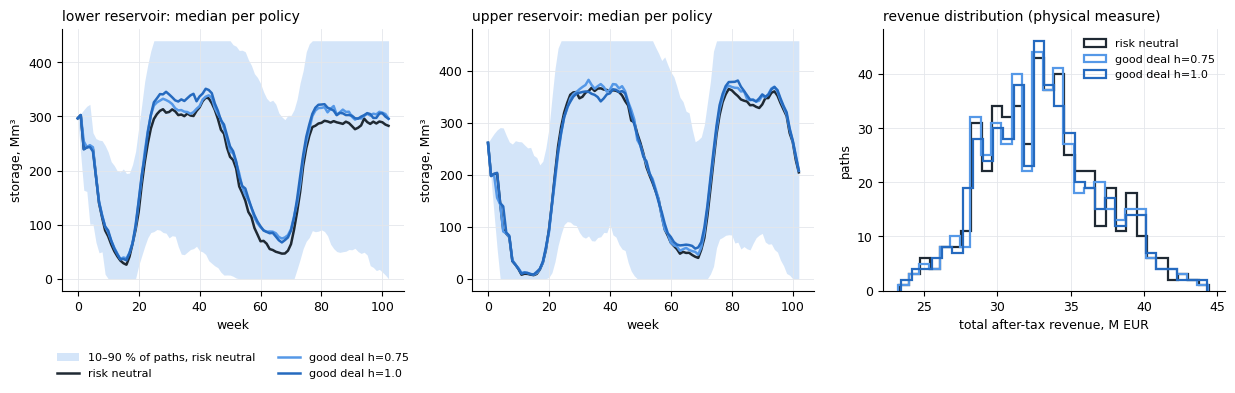

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
plots.storage_fan(sims, which=1, label="lower", ax=axes[0])
plots.storage_fan(sims, which=0, label="upper", ax=axes[1], legend=False)
plots.revenue_hist(sims, ax=axes[2])
fig.savefig(OUT / "fig_storage_revenue.png", dpi=130, bbox_inches="tight")

## Where does the worst-case measure spend its budget?

For the last good-deal policy the recorded $q^*$ of every node tells by how much the distorted expectation of next
week's inflow and price is shifted relative to the physical one (in standard deviations). With the forwards alive the
price shift is close to zero (the martingale constraints forbid it) and the budget goes to the inflows (negative:
the adversary makes next week drier). With the eight-contract set above a contract is live in every week, so the price shift stays near zero over the whole horizon. The inflow shift is negative except for the lower reservoir around the spring flood (weeks 5–35), where it turns positive: with the reservoir near full, extra inflow is spilled, so there the costly direction is wetter, not drier. Where no contract is alive the price can be distorted as well (remove the second-year contracts to see it).

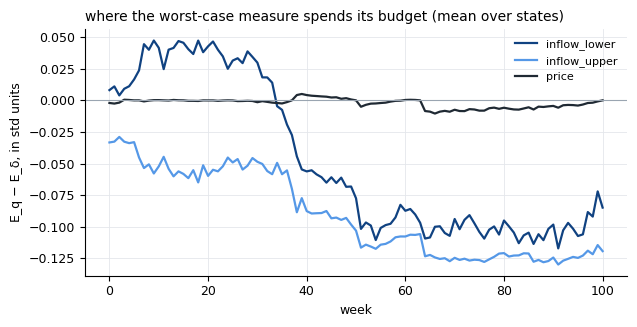

mean share of the chi-squared budget used: 1.000


In [8]:
last_gd = policies[f"good deal h={H_VALUES[-1]}"]
plots.distortion_tilt(last_gd, lattice)
plt.gcf().savefig(OUT / "fig_distortion.png", dpi=130, bbox_inches="tight")
print(f"mean share of the chi-squared budget used: {np.mean(list(last_gd.budget_used.values())):.3f}")

## Save the results

In [9]:
out = OUT
lattice.save(out / "lattice.npz")
table.to_csv(out / "summary.csv")
for name, pol in policies.items():
    tag = name.replace(" ", "_").replace("=", "")
    pol.history.to_csv(out / f"history_{tag}.csv", index=False)
    np.savez_compressed(out / f"cuts_{tag}.npz", cuts=np.array([(t, m, *c) for t in range(T) for m in range(K) for c in pol.cuts[t][m]]))
    np.savez_compressed(out / f"sim_{tag}.npz", **sims[name])
save_json({"T": T, "K": K, "h_values": H_VALUES, "contracts": [(c.id, c.start, c.end) for c in contracts], "price": vars(price),
           "coupling": coupling, "economics": vars(econ), "cascade": {"upper": vars(cascade.upper), "lower": vars(cascade.lower)}}, out / "config.json")
print("saved to", out.relative_to(ROOT)); sorted(p.name for p in out.iterdir())

saved to results/full_8c


['config.json', 'cuts_good_deal_h0.75.npz', 'cuts_good_deal_h1.0.npz', 'cuts_risk_neutral.npz', 'fig_convergence.png', 'fig_distortion.png', 'fig_lattice.png', 'fig_storage_revenue.png', 'history_good_deal_h0.75.csv', 'history_good_deal_h1.0.csv', 'history_risk_neutral.csv', 'lattice.npz', 'sim_good_deal_h0.75.npz', 'sim_good_deal_h1.0.npz', 'sim_risk_neutral.npz', 'summary.csv']